In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget 

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun

import geodesiq as gq

In [3]:
def dqd_hamiltonian(eps, U, tc, Ez, dEz, dEx):
    ham = np.array(
        [
            [U - eps, 0, -tc, tc, 0],
            [0, Ez, dEx, -dEx, 0],
            [-tc, dEx, dEz, 0, dEx],
            [tc, -dEx, 0, -dEz, -dEx],
            [0, 0, dEx, -dEx, -Ez],
        ]
    )
    return ham

# Adiabatic transfer

In [4]:
# ----- Set system and control parameters -----
alpha, beta = 2, 2

U, tc, Ez, dEz, dEx = 10, 1, 0.9, 0.1, 0.01
eps0, epsf = 15, 0

dqd_model = gq.ControlModel(H_c=dqd_hamiltonian(1, 0, 0, 0, 0, 0), H_d=dqd_hamiltonian(0, U, tc, Ez, dEz, dEx))
dqd_model.set_control(
    control_name="eps",
    pulse_initial=eps0,
    pulse_final=epsf,
    initial_state=0,
    final_state=0,
    alpha=alpha,
    beta=beta,
)

In [5]:
def compute_fidelity_vs_time(duration, model, alpha, beta):
    model.set_control(alpha=alpha, beta=beta)
    model.solve_problem(pulse_accuracy=int(1000))

    dynamics = gq.Dynamics(duration=duration, model=model)
    return dynamics.state_fidelity()


alphas = np.linspace(-5, 5, 10)
betas = np.linspace(-5, 5, 10)
durations = np.linspace(0.01, 1000, 20) / tc

fidelities = parameterrun(
    compute_fidelity_vs_time, ["duration", "alpha", "beta"], [durations, alphas, betas], model=dqd_model
)

best_fidelity = np.max(fidelities, axis=0)
best_duration = durations[np.argmax(fidelities, axis=0)]

compute_fidelity_vs_time: [['duration'],(...)]:   0%|          | 0/2000 [00:00<?, ?it/s]

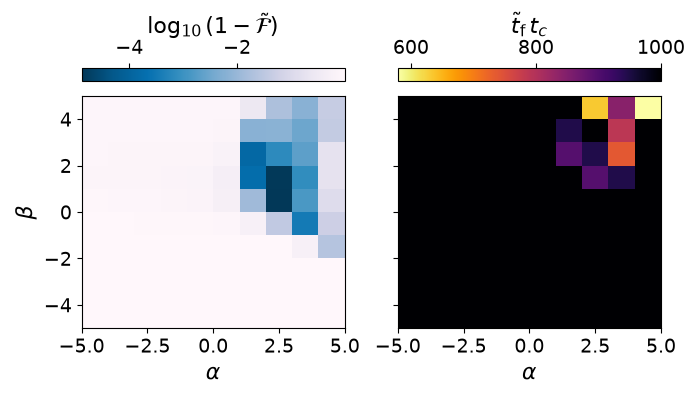

In [6]:
fontsizes = 14
fontsize_label = 16
colorbar_loc = "top"
cmap_coloring_fid = "PuBu_r"
extent = [min(alphas), max(alphas), min(betas), max(betas)]

fig, axs = plt.subplots(1, 2, figsize=(7, 4), sharey=True)

# --- Left Plot: Optimal Fidelity ---
fidelity_error = np.log10(1 - best_fidelity.T)

im0 = axs[0].imshow(
    fidelity_error, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap=cmap_coloring_fid
)
axs[0].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[0].set_ylabel(r"$\beta$", fontsize=fontsize_label)
axs[0].tick_params(labelsize=fontsizes)

cbar0 = plt.colorbar(im0, ax=axs[0], location=colorbar_loc, pad=0.05)
cbar0.set_label(r"$\log_{10}(1 - \tilde{\mathcal{F}})$", size=fontsize_label)
cbar0.ax.tick_params(labelsize=fontsizes)

# --- Right Plot: Best Times ---
im1 = axs[1].imshow(
    best_duration.T, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap="inferno_r"
)
axs[1].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[1].tick_params(labelsize=fontsizes)

cbar1 = plt.colorbar(im1, ax=axs[1], location=colorbar_loc, pad=0.05)
cbar1.set_label(r"$\tilde{t}_\text{f}\,t_c$", size=fontsize_label)
cbar1.ax.tick_params(labelsize=fontsizes)

plt.tight_layout()
plt.show();

# Diabatic transfer

In [7]:
# ----- Set system and control parameters -----
alpha, beta = 2, 2
dia_alpha, dia_beta = 0, 0

U, tc, Ez, dEz, dEx = 10, 1, 0.9, 0.1, 0.01
eps0, epsf = 15, 0

dqd_model = gq.ControlModel(H_c=dqd_hamiltonian(1, 0, 0, 0, 0, 0), H_d=dqd_hamiltonian(0, U, tc, Ez, dEz, dEx))
dqd_model.set_control(
    control_name="eps",
    pulse_initial=eps0,
    pulse_final=epsf,
    initial_state=0,
    final_state=1,
    alpha=alpha,
    beta=beta,
    dia_alpha=dia_alpha,
    dia_beta=dia_beta,
)

In [8]:
def compute_fidelity_vs_time(duration, model, dia_alpha, dia_beta):
    model.set_control(dia_alpha=dia_alpha, dia_beta=dia_beta)
    model.solve_problem(pulse_accuracy=int(1000))

    dynamics = gq.Dynamics(duration=duration, model=model)
    return dynamics.state_fidelity()


dia_alphas = np.linspace(-5, 5, 10)
dia_betas = np.linspace(-5, 5, 10)
durations = np.linspace(0.01, 1000, 20) / tc

fidelities = parameterrun(
    compute_fidelity_vs_time, ["duration", "dia_alpha", "dia_beta"], [durations, dia_alphas, dia_betas], model=dqd_model
)

best_fidelity = np.max(fidelities, axis=0)
best_duration = durations[np.argmax(fidelities, axis=0)]

compute_fidelity_vs_time: [['duration'],(...)]:   0%|          | 0/2000 [00:00<?, ?it/s]

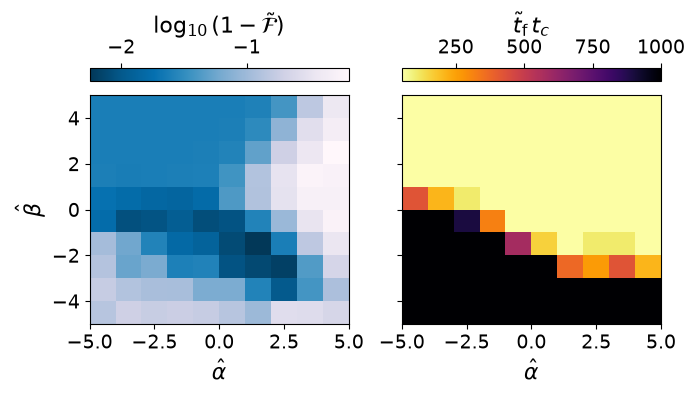

In [9]:
fontsizes = 14
fontsize_label = 16
colorbar_loc = "top"
cmap_coloring_fid = "PuBu_r"
extent = [min(dia_alphas), max(dia_alphas), min(dia_betas), max(dia_betas)]

fig, axs = plt.subplots(1, 2, figsize=(7, 4), sharey=True)

# --- Left Plot: Optimal Fidelity ---
fidelity_error = np.log10(1 - best_fidelity.T)

im0 = axs[0].imshow(
    fidelity_error, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap=cmap_coloring_fid
)
axs[0].set_xlabel(r"$\hat{\alpha}$", fontsize=fontsize_label)
axs[0].set_ylabel(r"$\hat{\beta}$", fontsize=fontsize_label)
axs[0].tick_params(labelsize=fontsizes)

cbar0 = plt.colorbar(im0, ax=axs[0], location=colorbar_loc, pad=0.05)
cbar0.set_label(r"$\log_{10}(1 - \tilde{\mathcal{F}})$", size=fontsize_label)
cbar0.ax.tick_params(labelsize=fontsizes)

# --- Right Plot: Best Times ---
im1 = axs[1].imshow(
    best_duration.T, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap="inferno_r"
)
axs[1].set_xlabel(r"$\hat{\alpha}$", fontsize=fontsize_label)
axs[1].tick_params(labelsize=fontsizes)

cbar1 = plt.colorbar(im1, ax=axs[1], location=colorbar_loc, pad=0.05)
cbar1.set_label(r"$\tilde{t}_\text{f}\,t_c$", size=fontsize_label)
cbar1.ax.tick_params(labelsize=fontsizes)

plt.tight_layout()
plt.show();